# Olist — comparação de modelos com CTGAN e PostgreSQL

**Experimento separado do modelo da aplicação.** Autorizado pela equipe em 11/11/2026:
até 10.000 atrasos **sintéticos somente no treino**. Avaliação exclusivamente em pedidos reais.
Não há garantia de melhora. A origem sintética e seus rótulos condicionantes são explícitos.

Esta cópia adapta o notebook `olist_comparacao_otimizada_gmm_treino_teste.ipynb`.
Preserva a ideia de comparar classificadores, GMM, limiares, matrizes e curvas PR.
O original foi copiado sem alteração. Aqui usamos os **29 atributos da aprovação**, o alvo
por **dia** e as partições do PostgreSQL usadas no `02_treinamento_modelos.ipynb`.
Não usamos tempo de postagem nem os quatro GMMs do original: esses atributos não existem
no contrato atual. O GMM opcional usa apenas distância e frete, conhecidos na aprovação.

**Pergunta:** acrescentar CTGAN melhora a identificação de atrasos em pedidos reais futuros,
comparado ao mesmo classificador sem os registros sintéticos?

### Resultado executado em 11/11/2026

- Gerados **10.000 registros sintéticos**, após 300 épocas do CTGAN e 13.398 candidatos amostrados.
- CSV final: **101.390 pedidos**, sendo 91.390 reais preservados e 10.000 sintéticos apenas no treino.
- PostgreSQL conferido por leitura de retorno; repetir a carga manteve exatamente 10.000 registros.
- **CTGAN reduziu o F1 nos cinco pares de modelos**, na validação e no teste real.
- Selecionada pela validação: **Regressão Logística com treino real**, sem promoção para a aplicação.

| Regressão Logística | Só reais | Reais + CTGAN |
|---|---:|---:|
| F1 validação | 26,97% | 23,86% |
| F1 teste descritivo | 14,94% | 12,96% |
| Accuracy teste | 68,36% | 74,72% |
| Recall teste | 63,17% | 42,79% |
| AP teste | 0,0963 | 0,0752 |

A accuracy aumentou nesse par, mas menos atrasos foram encontrados e F1/AP pioraram.
Os sintéticos não resolveram o problema nesta configuração. O peso mediano gerado
(562,5 g) também ficou abaixo do observado nos atrasos de treino (1.000 g), mostrando
que respeitar limites não significa reproduzir perfeitamente a distribuição real.
Uma seed e períodos já explorados não bastam para concluir sobre todas as configurações
possíveis de CTGAN. Não ajustar este experimento olhando o teste.

A execução inicial produziu avisos de compatibilidade das bibliotecas e de encerramento
paralelo no Windows, mas completou as 12 células de código. A chamada da GAN passou a
usar threads para novas gerações. Gráficos e métricas estão salvos abaixo e no diretório
`Modelos/experimento_ctgan/ecc4ac30a3df7383/`.


### 1. Ambiente e execução

No VS Code, selecione o interpretador **`.venv-ctgan/Scripts/python.exe`** como kernel.
Execute as células em ordem, com o PostgreSQL do projeto ligado.
Na máquina preparada, esse ambiente reutiliza bibliotecas da `.venv` por um arquivo `.pth`,
mas mantém Pandas/CTGAN próprios. Não mova as pastas sem recriar o ambiente.
Em outra máquina, crie um ambiente independente a partir da raiz:

```powershell
python -m venv .venv-ctgan
.\.venv-ctgan\Scripts\python.exe -m pip install -r requirements-ctgan.txt
```

Credenciais são lidas do `.env` existente, nunca incorporadas ao notebook.
**A execução grava** em `experimentos_ctgan.pedidos` / `experimentos_ctgan.execucoes`
e em `Dados/pedidos_tratados_e_injetados.csv`. Não escreve nas tabelas reais.
O cache local evita retreinar a GAN ao repetir a mesma configuração.

In [1]:
from pathlib import Path
import sys, os, json, hashlib, time
from importlib.metadata import version
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import torch
from IPython.display import display
from threadpoolctl import threadpool_limits

raiz = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src' / 'tratar_dados_ml.py').is_file())
if str(raiz) not in sys.path:
    sys.path.insert(0, str(raiz))
from src.experimento_ctgan import (
    consultar_base, hash_base, ajustar_gerador, gerar_atrasos,
    validar_injecao, persistir_experimento, VERSAO,
)
from src.tratar_dados_ml import criar_preprocessador
from src.preparar_dados import COLUNAS_PREVISAO

SEMENTE = 42
EPOCAS_CTGAN = 300
QUANTIDADE_SINTETICOS = 10_000  # Limite máximo verificado também antes da carga.
FRACAO_FILA = 0.10
np.random.seed(SEMENTE)
torch.manual_seed(SEMENTE)
torch.set_num_threads(4)
limite_threads = threadpool_limits(limits=4)
versoes = {p: version(p) for p in ['pandas', 'numpy', 'scikit-learn', 'torch', 'ctgan', 'rdt']}
display(pd.Series(versoes, name='versao'))
plt.rcParams.update({'figure.figsize': (10, 5), 'font.size': 11, 'axes.spines.top': False, 'axes.spines.right': False})

pandas               2.3.3
numpy                2.5.4
scikit-learn         1.9.1
torch           2.15.0+cpu
ctgan               0.13.0
rdt                  2.1.0
Name: versao, dtype: object

### 2. Dados reais diretamente do PostgreSQL

A consulta junta a view de inferência com o alvo de `public.pedidos`, sem multiplicar pedidos.
Mantemos os cortes em 01/01/2018 e 01/05/2018 e a seleção atual de rótulos conhecidos.
A revisão de disponibilidade do rótulo discutida no notebook 02 **não é misturada** neste teste.
O alvo significa entrega após o dia prometido, restrito a pedidos entregues elegíveis.
Disponibilidade de cadastros/pagamentos na aprovação permanece uma hipótese da base Olist.

In [2]:
base_real = consultar_base()
hash_snapshot = hash_base(base_real)
partes = {p: base_real.loc[base_real.particao.eq(p)].copy().reset_index(drop=True)
          for p in ['treino', 'validacao', 'teste']}
resumo_base = base_real.groupby('particao').agg(pedidos=('order_id', 'size'), atrasos=('atrasou', 'sum'))
resumo_base['taxa_atraso_%'] = 100 * resumo_base.atrasos / resumo_base.pedidos
display(resumo_base.round(2))
assert all(parte.atrasou.nunique() == 2 for parte in partes.values())
assert not any(c in COLUNAS_PREVISAO for c in ['atrasou', 'dias_atraso', 'order_id', 'rotulo_disponivel_em', 'origem_dado'])

,pedidos,atrasos,taxa_atraso_%
particao,,,
teste,25550,1124,4.40
treino,41173,1765,4.29
validacao,24667,2494,10.11


### 3. CTGAN aprende somente os atrasos reais do treino

Aprendemos **P(atributos | atraso)**; `atrasou=1` nos exemplos gerados é uma classe
sintética condicionante, não uma entrega observada. Os demais pedidos reais de treino
continuam presentes. Não fazemos undersampling nem geramos validação/teste.

Os contadores relacionados e as flags de ausência são codificados conjuntamente, preservando
estruturas observadas (por exemplo, vendedores não excedem itens). Valores contínuos usam
`log1p`; imputação, limites e categorias vêm somente dos atrasos de treino.
IDs e datas de entrega não entram na GAN. Datas históricas dos sintéticos ficam vazias.

In [3]:
configuracao = {'versao': VERSAO, 'semente': SEMENTE, 'epocas': EPOCAS_CTGAN,
               'quantidade': QUANTIDADE_SINTETICOS, 'hash_treino': hash_base(partes['treino']),
               'hash_codigo': hashlib.sha256((raiz / 'src/experimento_ctgan.py').read_bytes()).hexdigest(),
               'versoes': versoes}
experimento_id = hashlib.sha256(json.dumps(configuracao, sort_keys=True).encode()).hexdigest()[:16]
pasta_resultados = raiz / 'Modelos' / 'experimento_ctgan' / experimento_id
pasta_resultados.mkdir(parents=True, exist_ok=True)
cache = pasta_resultados / 'geracao.joblib'
inicio = time.perf_counter()
if cache.exists():
    pacote_salvo = joblib.load(cache)  # Somente cache local gerado por este projeto.
    assert pacote_salvo['configuracao'] == configuracao
    pacote = pacote_salvo['pacote']
    sinteticos = pacote_salvo['sinteticos']
    qualidade_geracao = pacote_salvo['qualidade']
    print('Cache local reutilizado:', experimento_id)
else:
    print('Treinando CTGAN somente nos atrasos reais do treino...', flush=True)
    # Threads evitam problemas de encerramento de subprocessos no Windows.
    with joblib.parallel_backend("threading", n_jobs=4):
        pacote = ajustar_gerador(partes['treino'], EPOCAS_CTGAN, SEMENTE)
    sinteticos, qualidade_geracao = gerar_atrasos(pacote, QUANTIDADE_SINTETICOS, experimento_id)
    joblib.dump({'configuracao': configuracao, 'pacote': pacote, 'sinteticos': sinteticos,
                 'qualidade': qualidade_geracao}, cache)
validar_injecao(base_real, sinteticos)
print('Segundos nesta célula:', round(time.perf_counter() - inicio, 1))
display(pd.Series(qualidade_geracao, name='contagem'))
display(sinteticos[['order_id', 'origem_dado', 'atrasou', 'rotulo_observado']].head())

Cache local reutilizado: ecc4ac30a3df7383
Segundos nesta célula: 0.9


candidatos_gerados    13398
sinteticos_aceitos    10000
Name: contagem, dtype: int64

,order_id,origem_dado,atrasou,rotulo_observado
0,ctgan_ecc4ac30a3df7383_00000,sintetico_ctgan,1,False
1,ctgan_ecc4ac30a3df7383_00001,sintetico_ctgan,1,False
2,ctgan_ecc4ac30a3df7383_00002,sintetico_ctgan,1,False
3,ctgan_ecc4ac30a3df7383_00003,sintetico_ctgan,1,False
4,ctgan_ecc4ac30a3df7383_00004,sintetico_ctgan,1,False


### 4. Plausibilidade e limitações dos exemplos gerados

Rejeitamos candidatos fora dos limites de treino e distâncias média/máxima inconsistentes.
Para um único vendedor, igualamos a distância média à máxima. Removemos cópias exatas
dos atrasos reais de treino e duplicatas sintéticas. Essas verificações **não comprovam
realismo, privacidade ou ganho preditivo**. Não há garantia de privacidade diferencial.

Comparamos distribuições apenas com os atrasos reais de treino. Diferenças grandes são
evidência de limitação da geração; não escolheremos amostras pelo desempenho no teste.

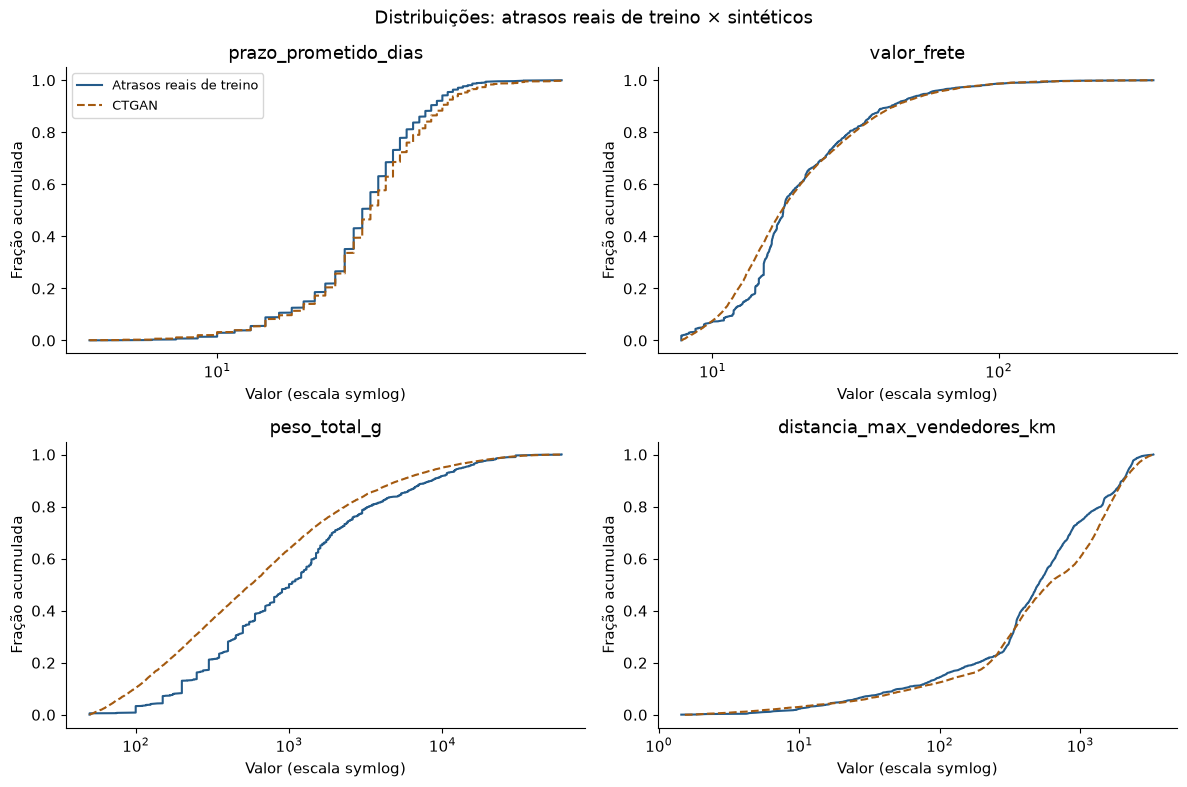

,atributo,mediana_real,mediana_sintetica,KS,ausentes_real_%,ausentes_sinteticos_%
0,prazo_prometido_dias,22.000,23.000,0.056,0.000,0.00
1,valor_frete,17.670,17.478,0.135,0.000,0.00
2,peso_total_g,1000.000,562.505,0.180,0.000,0.00
3,distancia_max_vendedores_km,504.279,595.157,0.149,0.623,1.16


In [4]:
from scipy.stats import ks_2samp
reais_atrasados = partes['treino'].loc[partes['treino'].atrasou.eq(1)]
colunas_qualidade = ['prazo_prometido_dias', 'valor_frete', 'peso_total_g', 'distancia_max_vendedores_km']
diagnostico_geracao = []
fig, eixos = plt.subplots(2, 2, figsize=(12, 8))
for coluna, ax in zip(colunas_qualidade, eixos.ravel()):
    a, b = reais_atrasados[coluna].dropna(), sinteticos[coluna].dropna()
    diagnostico_geracao.append({'atributo': coluna, 'mediana_real': a.median(),
                              'mediana_sintetica': b.median(), 'KS': ks_2samp(a, b).statistic,
                              'ausentes_real_%': 100 * reais_atrasados[coluna].isna().mean(),
                              'ausentes_sinteticos_%': 100 * sinteticos[coluna].isna().mean()})
    for serie, nome, cor, estilo in [(a, 'Atrasos reais de treino', '#245B8A', '-'),
                                    (b, 'CTGAN', '#A45A10', '--')]:
        xs = np.sort(serie.to_numpy())
        ax.plot(xs, np.arange(1, len(xs)+1)/len(xs), label=nome, color=cor, linestyle=estilo)
    ax.set_xscale('symlog', linthresh=1)
    ax.set(title=coluna, ylabel='Fração acumulada', xlabel='Valor (escala symlog)')
eixos[0, 0].legend(fontsize=9)
fig.suptitle('Distribuições: atrasos reais de treino × sintéticos')
fig.tight_layout()
fig.savefig(pasta_resultados / 'qualidade_ctgan.png', dpi=140, bbox_inches='tight')
plt.show()
display(pd.DataFrame(diagnostico_geracao).round(3))

### 5. Persistência isolada no PostgreSQL e CSV

O schema `experimentos_ctgan` guarda os sintéticos e o registro da execução (configuração,
hashes e versões). Reexecutar a mesma carga não duplica o lote. Os pedidos reais, a view e
o modelo da aplicação permanecem intactos. Cada experimento aceita no máximo 10.000 sintéticos.
O CSV solicitado reúne as três partições reais e o acréscimo **somente em treino**.
Nunca remova `particao`, `origem_dado` e `rotulo_observado` antes de separar as bases.

In [5]:
metadados_execucao = {**configuracao, 'hash_snapshot': hash_snapshot, 'geracao': qualidade_geracao,
                     'fonte': 'PostgreSQL: public.vw_pedidos_inferencia JOIN public.pedidos',
                     'predicao_em': 'aprovacao', 'alvo_sintetico': 'classe condicionante, nao observado',
                     'cortes': ['2018-01-01', '2018-05-01']}
arquivo_csv = persistir_experimento(base_real, sinteticos, metadados_execucao)
exportado = pd.read_csv(arquivo_csv, low_memory=False)
assert exportado.order_id.is_unique
assert not exportado.loc[exportado.particao.ne('treino'), 'origem_dado'].ne('real_olist').any()
assert hash_base(consultar_base()) == hash_snapshot
print('CSV:', arquivo_csv)
display(exportado.groupby(['particao', 'origem_dado']).size().rename('pedidos').to_frame())

C:\Users\ghost\OneDrive\Documentos\ChatGPT\Nikolas\BootcampTCS\EntregaCertaAI\src\experimento_ctgan.py:249: DtypeWarning: Columns (2,32) have mixed types. Specify dtype option on import or set low_memory=False.
  conferido = pd.read_csv(caminho)


CSV: C:\Users\ghost\OneDrive\Documentos\ChatGPT\Nikolas\BootcampTCS\EntregaCertaAI\Dados\pedidos_tratados_e_injetados.csv


pedidos
particao  origem_dado             
teste     real_olist         25550
treino    real_olist         41173
          sintetico_ctgan    10000
validacao real_olist         24667

### 6. Mesmas entradas e mesmas avaliações para os dois cenários

Ajustamos o pré-processador **uma única vez no treino real**, depois o reutilizamos nos
dois cenários. Isso isola o efeito do acréscimo de exemplos. O teste não participa da
geração, ajuste de modelos, GMM ou escolha de limiar.

In [6]:
preprocessador = criar_preprocessador()
X = {'treino': preprocessador.fit_transform(partes['treino'][COLUNAS_PREVISAO]).astype(np.float32)}
for p in ['validacao', 'teste']:
    X[p] = preprocessador.transform(partes[p][COLUNAS_PREVISAO]).astype(np.float32)
X_sintetico = preprocessador.transform(sinteticos[COLUNAS_PREVISAO]).astype(np.float32)
y = {p: partes[p].atrasou.to_numpy(dtype=int) for p in partes}
cenarios = {
    'Real': (X['treino'], y['treino']),
    'Real + CTGAN': (np.concatenate([X['treino'], X_sintetico]),
                     np.concatenate([y['treino'], sinteticos.atrasou.to_numpy(dtype=int)])),
}
print('Atributos transformados:', X['treino'].shape[1])
display(pd.DataFrame([{'cenario': nome, 'pedidos': len(yt), 'atrasos': int(yt.sum()),
                      'taxa_atraso_%': 100*yt.mean()} for nome, (_, yt) in cenarios.items()]))

Atributos transformados: 159


,cenario,pedidos,atrasos,taxa_atraso_%
0,Real,41173,1765,4.28679
1,Real + CTGAN,51173,11765,22.99064


### 7. GMM de distância/frete (comparação opcional)

O GMM agrupa padrões, não classifica atraso. Aprende apenas no treino real e acrescenta
quatro probabilidades de grupo. A mesma transformação é usada com e sem CTGAN.

In [7]:
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.mixture import GaussianMixture
colunas_gmm = ['distancia_max_vendedores_km', 'valor_frete']
pre_gmm = make_pipeline(SimpleImputer(strategy='median'), StandardScaler())
gmm = GaussianMixture(n_components=4, covariance_type='full', reg_covar=1e-5, random_state=SEMENTE)
gmm.fit(pre_gmm.fit_transform(partes['treino'][colunas_gmm]))
X_gmm = {p: np.column_stack([X[p], gmm.predict_proba(pre_gmm.transform(partes[p][colunas_gmm]))]).astype(np.float32)
         for p in partes}
sint_gmm = np.column_stack([X_sintetico, gmm.predict_proba(pre_gmm.transform(sinteticos[colunas_gmm]))]).astype(np.float32)

### 8. Métricas e limiar escolhido na validação

Critério deste experimento: **F1 da classe atraso**, desempate por Average Precision (AP).
O limiar é escolhido na validação real, não nos sintéticos. Accuracy aparece junto com
precision, recall, F1, AP e matriz de confusão. Também medimos a fila fixa de 10% para
comparar com a política da aplicação: ela pode produzir um resultado diferente do limiar F1.
Os scores após aumento da classe positiva **não são probabilidades calibradas**.

In [8]:
from sklearn.metrics import (precision_recall_curve, average_precision_score, accuracy_score,
    precision_score, recall_score, f1_score, balanced_accuracy_score,
    confusion_matrix, ConfusionMatrixDisplay, PrecisionRecallDisplay)

def escolher_limiar(alvo, scores):
    precisao, recall, limites = precision_recall_curve(alvo, scores)
    f1 = 2 * precisao[:-1] * recall[:-1] / np.maximum(precisao[:-1] + recall[:-1], 1e-12)
    return float(limites[np.argmax(f1)])

def metricas(alvo, scores, limiar):
    previstos = (scores >= limiar).astype(int)
    tn, fp, fn, tp = confusion_matrix(alvo, previstos, labels=[0, 1]).ravel()
    fila = np.zeros(len(scores), dtype=int)
    k = int(len(scores) * FRACAO_FILA)
    fila[np.argsort(-scores, kind='stable')[:k]] = 1
    return {'n': len(alvo), 'taxa_atraso': alvo.mean(), 'limiar': limiar,
            'accuracy': accuracy_score(alvo, previstos),
            'balanced_accuracy': balanced_accuracy_score(alvo, previstos),
            'precision': precision_score(alvo, previstos, zero_division=0),
            'recall': recall_score(alvo, previstos, zero_division=0),
            'f1': f1_score(alvo, previstos, zero_division=0),
            'AP': average_precision_score(alvo, scores),
            'tn': int(tn), 'fp': int(fp), 'fn': int(fn), 'tp': int(tp),
            'pedidos_top10': k, 'atrasos_top10': int(alvo[fila == 1].sum()),
            'precision_top10': precision_score(alvo, fila, zero_division=0),
            'recall_top10': recall_score(alvo, fila, zero_division=0)}

### 9. Treinamento controlado

Regressão Logística, Random Forest, Extra Trees e HGB, mais RF com GMM.
Parâmetros fixos, mesma seed e pré-processamento para cada par: Real × Real + CTGAN.
Sem busca extensa nesta primeira avaliação. Incluímos também uma regressão com pesos
de classe, sem sintéticos, como alternativa simples. HGB não usa divisão aleatória interna
para parada antecipada. A MLP de produção fica preservada para uma comparação posterior.

In [9]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, HistGradientBoostingClassifier
from sklearn.base import clone
catalogo = {
    'Logistica': LogisticRegression(C=1, max_iter=1500, solver='liblinear', random_state=SEMENTE),
    'Random Forest': RandomForestClassifier(n_estimators=180, max_depth=14, min_samples_leaf=8, n_jobs=4, random_state=SEMENTE),
    'Extra Trees': ExtraTreesClassifier(n_estimators=180, max_depth=18, min_samples_leaf=8, n_jobs=4, random_state=SEMENTE),
    'HGB': HistGradientBoostingClassifier(max_iter=180, max_leaf_nodes=15, learning_rate=.05,
                                         l2_regularization=1, early_stopping=False, random_state=SEMENTE),
    'RF + GMM': RandomForestClassifier(n_estimators=180, max_depth=14, min_samples_leaf=8, n_jobs=4, random_state=SEMENTE),
}
modelos, resultados_val, scores_val = {}, [], {}
for nome, estimador in catalogo.items():
    for cenario, (xt, yt) in cenarios.items():
        usa_gmm = nome == 'RF + GMM'
        if usa_gmm:
            xt = X_gmm['treino'] if cenario == 'Real' else np.concatenate([X_gmm['treino'], sint_gmm])
        modelo = clone(estimador).fit(xt, yt)
        scores = modelo.predict_proba(X_gmm['validacao'] if usa_gmm else X['validacao'])[:, 1]
        limiar = escolher_limiar(y['validacao'], scores)
        chave = (nome, cenario)
        modelos[chave] = {'modelo': modelo, 'limiar': limiar, 'usa_gmm': usa_gmm}
        scores_val[chave] = scores
        resultados_val.append({'modelo': nome, 'cenario': cenario, **metricas(y['validacao'], scores, limiar)})
        print(nome, '|', cenario, '| F1 validação:', round(resultados_val[-1]['f1'], 4), flush=True)

# Controle simples: pesos de classe em dados reais, sem CTGAN.
controle = LogisticRegression(C=1, class_weight='balanced', max_iter=1500, solver='liblinear', random_state=SEMENTE).fit(X['treino'], y['treino'])
sc = controle.predict_proba(X['validacao'])[:, 1]
lim = escolher_limiar(y['validacao'], sc)
chave = ('Logistica com pesos', 'Real')
modelos[chave] = {'modelo': controle, 'limiar': lim, 'usa_gmm': False}
scores_val[chave] = sc
resultados_val.append({'modelo': chave[0], 'cenario': chave[1], **metricas(y['validacao'], sc, lim)})
tabela_validacao = pd.DataFrame(resultados_val).sort_values(['f1', 'AP'], ascending=False)
escolhido = tuple(tabela_validacao.iloc[0][['modelo', 'cenario']])
print('Escolhido ANTES do teste:', escolhido)
display(tabela_validacao[['modelo', 'cenario', 'accuracy', 'precision', 'recall', 'f1', 'AP', 'atrasos_top10']].round(4))
print('Accuracy de sempre prever no prazo:', round(1 - y['validacao'].mean(), 4), '| F1 atraso = 0')

Logistica | Real | F1 validação: 0.2697


Logistica | Real + CTGAN | F1 validação: 0.2386


Random Forest | Real | F1 validação: 0.2369


Random Forest | Real + CTGAN | F1 validação: 0.1976


Extra Trees | Real | F1 validação: 0.2595


Extra Trees | Real + CTGAN | F1 validação: 0.2505


... (3 outputs left out)

RF + GMM | Real + CTGAN | F1 validação: 0.1931


Escolhido ANTES do teste: ('Logistica', 'Real')


,modelo,cenario,accuracy,precision,recall,f1,AP,atrasos_top10
0,Logistica,Real,0.8127,0.2227,0.3420,0.2697,0.1986,619
10,Logistica com pesos,Real,0.7954,0.2055,0.3573,0.2609,0.1893,571
4,Extra Trees,Real,0.7656,0.1907,0.4062,0.2595,0.1694,516
5,Extra Trees,Real + CTGAN,0.6457,0.1593,0.5854,0.2505,0.1448,391
1,Logistica,Real + CTGAN,0.7438,0.1705,0.3970,0.2386,0.1587,452
8,RF + GMM,Real,0.6979,0.1594,0.4651,0.2374,0.1663,500
2,Random Forest,Real,0.6712,0.1548,0.5048,0.2369,0.1708,491
6,HGB,Real,0.5594,0.1311,0.5966,0.2150,0.1510,411
7,HGB,Real + CTGAN,0.6366,0.1292,0.4519,0.2009,0.1345,402
3,Random Forest,Real + CTGAN,0.4476,0.1158,0.6728,0.1976,0.1315,392


Accuracy de sempre prever no prazo: 0.8989 | F1 atraso = 0


### 10. Avaliação descritiva no teste real

Modelos e limiares já foram congelados. O teste serve para relatar, nunca para escolher
quantidade sintética, epochs ou modelo. Como esse período já foi consultado em experimentos
anteriores do projeto, **não é um holdout virgem**; uma conclusão confirmatória exigirá
outro período externo ou um protocolo temporal adicional definido antes dos resultados.

In [10]:
resultados_teste, scores_teste = [], {}
for chave, pacote_modelo in modelos.items():
    matriz = X_gmm['teste'] if pacote_modelo['usa_gmm'] else X['teste']
    sc = pacote_modelo['modelo'].predict_proba(matriz)[:, 1]
    scores_teste[chave] = sc
    resultados_teste.append({'modelo': chave[0], 'cenario': chave[1],
                            **metricas(y['teste'], sc, pacote_modelo['limiar'])})
tabela_teste = pd.DataFrame(resultados_teste)
display(tabela_teste[['modelo', 'cenario', 'accuracy', 'precision', 'recall', 'f1', 'AP', 'fp', 'fn', 'atrasos_top10']].round(4))
print('Accuracy de sempre prever no prazo:', round(1 - y['teste'].mean(), 4), '| F1 atraso = 0')

,modelo,cenario,accuracy,precision,recall,f1,AP,fp,fn,atrasos_top10
0,Logistica,Real,0.6836,0.0847,0.6317,0.1494,0.0963,7671,414,288
1,Logistica,Real + CTGAN,0.7472,0.0764,0.4279,0.1296,0.0752,5816,643,213
2,Random Forest,Real,0.5947,0.0743,0.7171,0.1347,0.0985,10037,318,330
3,Random Forest,Real + CTGAN,0.2996,0.0480,0.7918,0.0905,0.0679,17660,234,196
4,Extra Trees,Real,0.7494,0.0684,0.3719,0.1155,0.0655,5697,706,186
5,Extra Trees,Real + CTGAN,0.6340,0.0523,0.4279,0.0933,0.0619,8708,643,211
6,HGB,Real,0.6174,0.0798,0.7304,0.1438,0.0947,9472,303,305
7,HGB,Real + CTGAN,0.7099,0.0668,0.4315,0.1157,0.0726,6774,639,231
8,RF + GMM,Real,0.6173,0.0764,0.6948,0.1377,0.0918,9436,343,286
9,RF + GMM,Real + CTGAN,0.4682,0.0509,0.6290,0.0943,0.0646,13171,417,191


Accuracy de sempre prever no prazo: 0.956 | F1 atraso = 0


### 11. Comparações, curvas Precision–Recall e matrizes de confusão

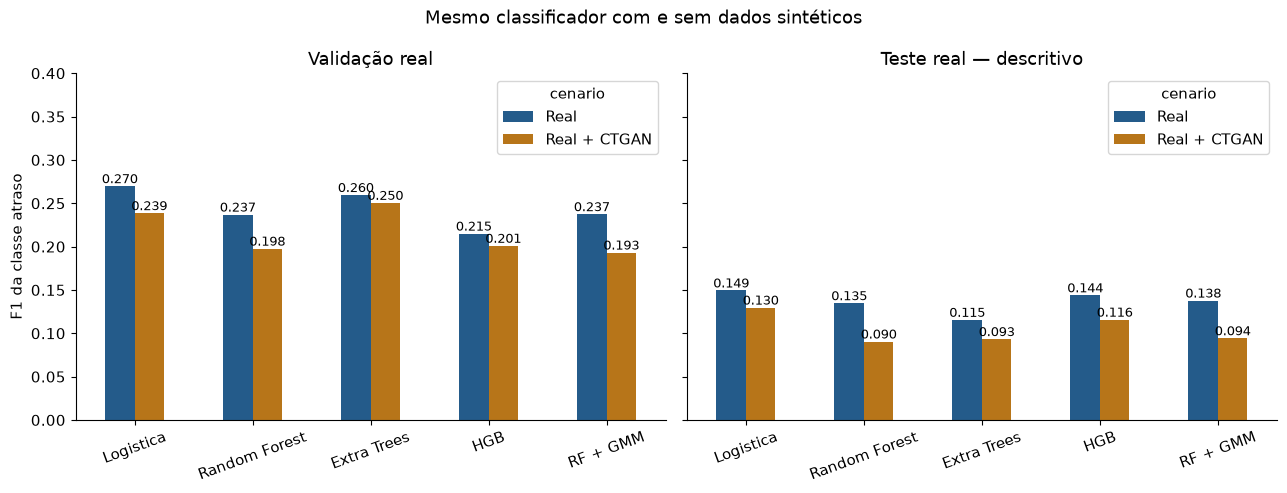

C:\Users\ghost\OneDrive\Documentos\ChatGPT\Nikolas\BootcampTCS\EntregaCertaAI\.venv\Lib\site-packages\sklearn\utils\_plotting.py:193: FutureWarning: `**kwargs` is deprecated and will be removed in 1.11. Pass all matplotlib arguments to `curve_kwargs` as a dictionary instead.
  warnings.warn(
C:\Users\ghost\OneDrive\Documentos\ChatGPT\Nikolas\BootcampTCS\EntregaCertaAI\.venv\Lib\site-packages\sklearn\utils\_plotting.py:193: FutureWarning: `**kwargs` is deprecated and will be removed in 1.11. Pass all matplotlib arguments to `curve_kwargs` as a dictionary instead.
  warnings.warn(
C:\Users\ghost\OneDrive\Documentos\ChatGPT\Nikolas\BootcampTCS\EntregaCertaAI\.venv\Lib\site-packages\sklearn\utils\_plotting.py:193: FutureWarning: `**kwargs` is deprecated and will be removed in 1.11. Pass all matplotlib arguments to `curve_kwargs` as a dictionary instead.
  warnings.warn(
C:\Users\ghost\OneDrive\Documentos\ChatGPT\Nikolas\BootcampTCS\EntregaCertaAI\.venv\Lib\site-packages\sklearn\utils\_plot

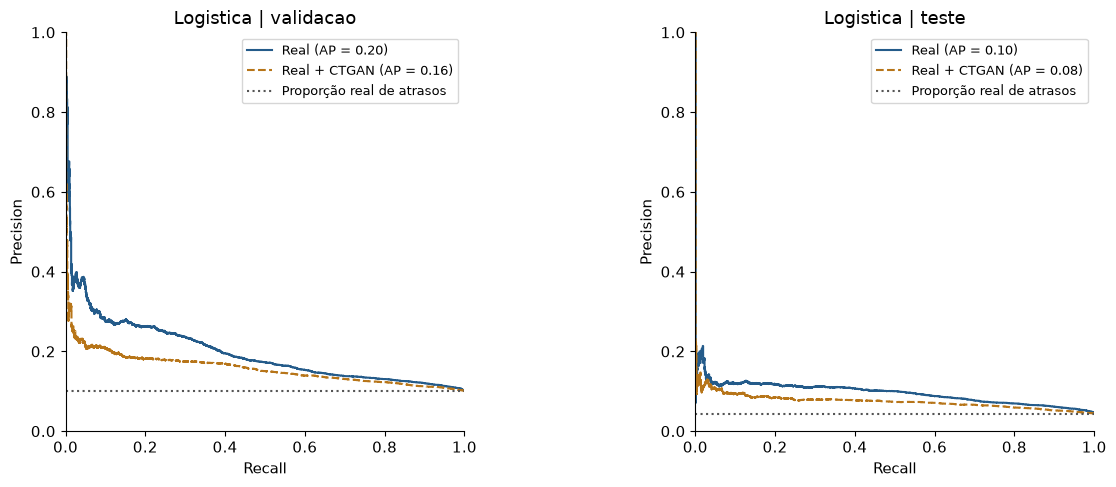

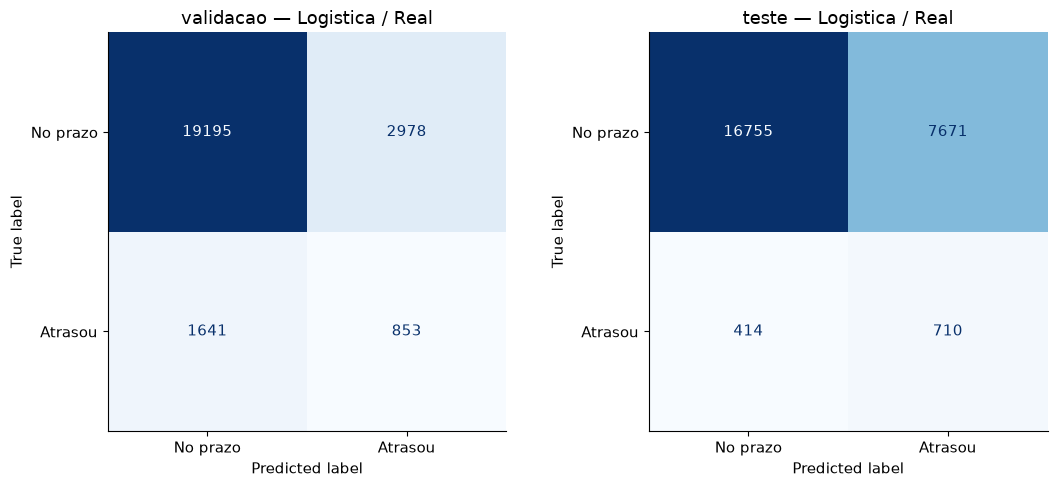

In [11]:
fig, eixos = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
for ax, tabela, titulo in zip(eixos, [tabela_validacao, tabela_teste], ['Validação real', 'Teste real — descritivo']):
    piv = tabela[tabela.modelo.isin(catalogo)].pivot(index='modelo', columns='cenario', values='f1').reindex(list(catalogo))
    piv[['Real', 'Real + CTGAN']].plot.bar(ax=ax, color=['#245B8A', '#B77519'], rot=20)
    ax.set(title=titulo, ylabel='F1 da classe atraso', xlabel='', ylim=(0, max(.4, piv.max().max()*1.2)))
    for barras in ax.containers:
        ax.bar_label(barras, fmt='%.3f', fontsize=9)
fig.suptitle('Mesmo classificador com e sem dados sintéticos')
fig.tight_layout()
fig.savefig(pasta_resultados / 'comparacao_f1.png', dpi=140, bbox_inches='tight')
plt.show()

fig, eixos = plt.subplots(1, 2, figsize=(13, 5))
familia = escolhido[0]
for ax, parte, dic_scores in zip(eixos, ['validacao', 'teste'], [scores_val, scores_teste]):
    for cenario, cor, estilo in [('Real', '#245B8A', '-'), ('Real + CTGAN', '#B77519', '--')]:
        chave = (familia, cenario)
        if chave in dic_scores:
            PrecisionRecallDisplay.from_predictions(y[parte], dic_scores[chave], name=cenario,
                ax=ax, color=cor, linestyle=estilo)
    ax.axhline(y[parte].mean(), color='#555555', linestyle=':', label='Proporção real de atrasos')
    ax.set(title=f'{familia} | {parte}', xlabel='Recall', ylabel='Precision', xlim=(0, 1), ylim=(0, 1))
    ax.legend(fontsize=9)
fig.tight_layout()
fig.savefig(pasta_resultados / 'curvas_pr.png', dpi=140, bbox_inches='tight')
plt.show()

fig, eixos = plt.subplots(1, 2, figsize=(11, 5))
for ax, parte, dic_scores in zip(eixos, ['validacao', 'teste'], [scores_val, scores_teste]):
    pred = (dic_scores[escolhido] >= modelos[escolhido]['limiar']).astype(int)
    ConfusionMatrixDisplay.from_predictions(y[parte], pred, labels=[0, 1], display_labels=['No prazo', 'Atrasou'],
                                           ax=ax, cmap='Blues', colorbar=False, values_format='d')
    ax.set_title(f'{parte} — {escolhido[0]} / {escolhido[1]}')
fig.tight_layout()
fig.savefig(pasta_resultados / 'matrizes_escolhido.png', dpi=140, bbox_inches='tight')
plt.show()

### 12. Salvar evidências e interpretação

Nada é promovido automaticamente para a API ou para o notebook 02.
Compare F1/AP e a fila de 10%: o CTGAN pode ajudar algumas métricas e piorar outras.
Uma seed e um período não demonstram estabilidade nem redução operacional de atrasos.
Dados sintéticos não corrigem, por si só, ausência de atributos ou mudanças entre períodos.

In [12]:
tabela_validacao.to_csv(pasta_resultados / 'metricas_validacao.csv', index=False)
tabela_teste.to_csv(pasta_resultados / 'metricas_teste.csv', index=False)
pd.DataFrame(diagnostico_geracao).to_csv(pasta_resultados / 'qualidade_geracao.csv', index=False)
joblib.dump({'preprocessador': preprocessador, 'pre_gmm': pre_gmm, 'gmm': gmm,
             'colunas_gmm': colunas_gmm, 'colunas_entrada': COLUNAS_PREVISAO,
             'modelos': modelos, 'escolhido_validacao': escolhido,
             'metadados': metadados_execucao}, pasta_resultados / 'modelos_comparacao.joblib')
for nome, tabela in [('validação', tabela_validacao), ('teste descritivo', tabela_teste)]:
    pares = tabela[tabela.modelo.isin(catalogo)].pivot(index='modelo', columns='cenario', values='f1')
    delta = pares['Real + CTGAN'] - pares['Real']
    print(f'{nome}: CTGAN aumentou F1 em {int(delta.gt(0).sum())} de {len(delta)} pares; diferenças em pontos percentuais:')
    display((100 * delta).rename('delta_F1_pp').round(2).to_frame())
print('Artefatos experimentais:', pasta_resultados)
print('Teste e validação permanecem reais. Modelo de produção preservado.')

validação: CTGAN aumentou F1 em 0 de 5 pares; diferenças em pontos percentuais:


,delta_F1_pp
modelo,
Extra Trees,-0.91
HGB,-1.40
Logistica,-3.11
RF + GMM,-4.43
Random Forest,-3.93


teste descritivo: CTGAN aumentou F1 em 0 de 5 pares; diferenças em pontos percentuais:


,delta_F1_pp
modelo,
Extra Trees,-2.22
HGB,-2.81
Logistica,-1.98
RF + GMM,-4.35
Random Forest,-4.42


Artefatos experimentais: C:\Users\ghost\OneDrive\Documentos\ChatGPT\Nikolas\BootcampTCS\EntregaCertaAI\Modelos\experimento_ctgan\ecc4ac30a3df7383
Teste e validação permanecem reais. Modelo de produção preservado.


### Referências e rastreabilidade

- [Olist — dados reais e licença CC BY-NC-SA 4.0](https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce).
- [CTGAN — implementação oficial](https://github.com/sdv-dev/CTGAN).
- [Learning to Model and Sample from Tabular Data (2019)](https://arxiv.org/abs/1907.00503).
- Regras de tratamento: `src/tratar_dados_ml.py`; consulta/geração/persistência: `src/experimento_ctgan.py`.
- Hashes e configurações ficam no cache e no registro PostgreSQL da execução.

Os sintéticos são derivados experimentais da base Olist, não novos registros observados.
Preserve atribuição e condições de uso da fonte. Avaliação em dados reais não transforma
os registros sintéticos em evidência de acontecimentos reais.